# Olist Delivery Performance & Customer Satisfaction

**Igor M. Lopes** · MS Business Analytics & Project Management, University of Connecticut
Based on the OPIM 5603 (Statistics in Business Analytics) Case 1 group project, re-run independently on the full public dataset.

## Business question
Management set three targets for the marketplace:

| Metric | Target |
|---|---|
| Average delivery time | ≤ 13 days |
| Late-delivery rate | ≤ 10% |
| Average review score | ≥ 4.20 |

This notebook tests each target with 95% confidence intervals, checks whether extreme delivery times distort the averages, and measures how delivery performance relates to customer ratings.

## Key findings
| Metric | Estimate | 95% CI | Result |
|---|---|---|---|
| Average delivery time | 12.09 days | 12.03 – 12.15 | ✅ Target met |
| Late-delivery rate | 7.87% | 7.71% – 8.04% | ✅ Target met |
| Average review score | 4.09 | 4.08 – 4.09 | ❌ Below target |

* Customers whose orders arrived on time rated **4.21** on average; late orders rated **2.57**.
* Late orders took a median of **29 days** vs **9 days** for on-time orders.
* **5,025 orders (5.2%)** took longer than 28.5 days. Removing them lowers the mean to 10.56 days, so the delivery-time conclusion is robust.
* Recommendation: the fastest route to the 4.20 review target is preventing late deliveries, not speeding up the average order.

**Data:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) · 99,441 orders, Sep 2016 – Oct 2018

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

# Works on Kaggle (input folder) and locally (put the CSVs in ../data or ./data)
candidates = list(Path('/kaggle/input').rglob('olist_orders_dataset.csv')) if Path('/kaggle/input').exists() else []
candidates += [p / 'olist_orders_dataset.csv' for p in (Path('../data'), Path('data'))]
DATA_DIR = next(p.parent for p in candidates if p.exists())

FIG_DIR = Path('../figures') if Path('../figures').exists() else Path('figures')
FIG_DIR.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'font.size': 12, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
LIGHT_BLUE, LIGHT_RED = '#ADD8E6', '#F08080'
print('Data folder:', DATA_DIR)

Data folder: ../data


## 2. Load data
Five of the nine Olist tables are used, joined on `order_id`, `customer_id` and `product_id`.

In [2]:
orders    = pd.read_csv(DATA_DIR / 'olist_orders_dataset.csv')
reviews   = pd.read_csv(DATA_DIR / 'olist_order_reviews_dataset.csv')
customers = pd.read_csv(DATA_DIR / 'olist_customers_dataset.csv')
items     = pd.read_csv(DATA_DIR / 'olist_order_items_dataset.csv')
products  = pd.read_csv(DATA_DIR / 'olist_products_dataset.csv')
category_en = pd.read_csv(DATA_DIR / 'product_category_name_translation.csv')

for name, df in {'orders': orders, 'reviews': reviews, 'customers': customers,
                 'items': items, 'products': products}.items():
    print(f'{name:<10} {df.shape[0]:>8,} rows  {df.shape[1]:>2} columns')

orders       99,441 rows   8 columns
reviews      99,224 rows   7 columns
customers    99,441 rows   5 columns
items       112,650 rows   7 columns
products     32,951 rows   9 columns


## 3. Data quality checks

In [3]:
print('Duplicate order IDs:', orders['order_id'].duplicated().sum())
print('Reviews cover', reviews['order_id'].nunique(), 'distinct orders (some orders have >1 review)')
print('Products without a category:', products['product_category_name'].isna().sum())
print('\nMissing values in orders:')
print(orders.isna().sum()[lambda s: s > 0])
print('\nOrder status:')
print(orders['order_status'].value_counts())

Duplicate order IDs: 0
Reviews cover 98673 distinct orders (some orders have >1 review)
Products without a category: 610

Missing values in orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Order status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


Missing values are confined to expected fields. The 2,965 orders without a customer delivery date were shipped, canceled, unavailable or still in progress, so they have no delivery time. No records were imputed and the source files were not edited.

## 4. Prepare variables

In [4]:
for col in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    orders[col] = pd.to_datetime(orders[col])

# Delivery time: purchase to customer delivery, in whole days
orders['delivery_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.days

# Delay: delivery date minus estimated date, in calendar days (negative = early)
orders['delay_days'] = (orders['order_delivered_customer_date'].dt.normalize()
                        - orders['order_estimated_delivery_date']).dt.days

# Late: delivered after the estimated delivery date (undelivered orders are False)
orders['late_delivery'] = orders['order_delivered_customer_date'] > orders['order_estimated_delivery_date']

delivered = orders[orders['delivery_days'].notna()].copy()
print(f'Orders with a delivery date: {len(delivered):,}')

# Consistency check: every late order should have a delay of 0 or more days
print('Late orders with negative delay:', (delivered['late_delivery'] & (delivered['delay_days'] < 0)).sum())
print('Late orders delivered ON the estimated date:', (delivered['late_delivery'] & (delivered['delay_days'] == 0)).sum())

Orders with a delivery date: 96,476
Late orders with negative delay: 0
Late orders delivered ON the estimated date: 1292


The estimated date has no time of day, so 1,292 orders delivered on the promised date itself count as late. This makes the late rate slightly conservative.

## 5. Descriptive statistics

In [5]:
order_value = items.groupby('order_id').agg(order_value=('price', 'sum'), freight=('freight_value', 'sum'))

def describe(x):
    x = x.dropna()
    q1, q3 = x.quantile([.25, .75])
    return pd.Series({'n': len(x), 'Mean': x.mean(), 'Median': x.median(), 'SD': x.std(),
                      'Q1': q1, 'Q3': q3, 'IQR': q3 - q1, 'Min': x.min(), 'Max': x.max(),
                      'Skewness': x.skew(), 'Excess kurtosis': x.kurt()})

table2 = pd.DataFrame({
    'Review score':      describe(reviews['review_score']),
    'Delivery (days)':   describe(delivered['delivery_days']),
    'Delay (days)':      describe(delivered['delay_days']),
    'Order value (BRL)': describe(order_value['order_value']),
    'Freight (BRL)':     describe(order_value['freight']),
})
table2

,Review score,Delivery (days),Delay (days),Order value (BRL),Freight (BRL)
n,"99,224.00","96,476.00","96,476.00","98,666.00","98,666.00"
Mean,4.09,12.09,-11.88,137.75,22.82
Median,5.00,10.00,-12.00,86.90,17.17
SD,1.35,9.55,10.18,210.65,21.65
Q1,4.00,6.00,-17.00,45.90,13.85
Q3,5.00,15.00,-7.00,149.90,24.04
IQR,1.00,9.00,10.00,104.00,10.19
Min,1.00,0.00,-147.00,0.85,0.00
Max,5.00,209.00,188.00,"13,440.00","1,794.96"
Skewness,-1.36,3.83,2.01,9.73,12.05


* **Review score:** polarized. The median is 5, but a tail of 1-star reviews (negative skew) pulls the mean down to 4.09.
* **Delivery time:** typical orders take 6–15 days, but the right skew and a 209-day maximum inflate the mean and SD.
* **Delay:** orders arrive about 12 days before the estimate on average, so estimates are conservative. A long right tail of late arrivals remains.
* **Order value and freight:** extremely right-skewed. The median (BRL 86.90) is a better summary of a typical order than the mean.

## 6. Late deliveries and order mix

In [6]:
late_n = int(orders['late_delivery'].sum())
print(f'Late orders: {late_n:,}')
print(f'Late rate, all {len(orders):,} orders:       {late_n/len(orders):.2%}')
print(f'Late rate, {len(delivered):,} delivered orders: {late_n/len(delivered):.2%}')

Late orders: 7,827
Late rate, all 99,441 orders:       7.87%
Late rate, 96,476 delivered orders: 8.11%


In [7]:
states = (orders.merge(customers, on='customer_id')['customer_state']
          .value_counts().head(5).to_frame('orders'))
states['%'] = states['orders'] / len(orders) * 100

cats = (items.merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
             .merge(category_en, on='product_category_name', how='left')
             .drop_duplicates(['order_id', 'product_category_name_english'])
             ['product_category_name_english'].value_counts().head(5).to_frame('orders'))
cats['%'] = cats['orders'] / items['order_id'].nunique() * 100
display(states, cats)

,orders,%
customer_state,,
SP,41746,41.98
RJ,12852,12.92
MG,11635,11.70
RS,5466,5.50
PR,5045,5.07


,orders,%
product_category_name_english,,
bed_bath_table,9417,9.54
health_beauty,8836,8.96
sports_leisure,7720,7.82
computers_accessories,6689,6.78
furniture_decor,6449,6.54


SP, RJ and MG account for two-thirds of orders. Demand is spread across many categories: no category appears in more than 10% of orders.

## 7. Outlier analysis (1.5 × IQR rule)

In [8]:
def outlier_summary(x, label):
    q1, q3 = x.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
    kept = x[x <= fence]
    rows = {'All orders': x, f'Excluding {(x > fence).sum():,} outliers (> {fence:,.2f})': kept}
    return pd.DataFrame({k: {'n': len(v), 'Mean': v.mean(), 'Median': v.median(), 'SD': v.std()}
                         for k, v in rows.items()}).T.assign(Variable=label)

pd.concat([outlier_summary(delivered['delivery_days'], 'Delivery (days)'),
           outlier_summary(order_value['order_value'], 'Order value (BRL)')])

,n,Mean,Median,SD,Variable
All orders,"96,476.00",12.09,10.00,9.55,Delivery (days)
"Excluding 5,025 outliers (> 28.50)","91,451.00",10.56,9.00,6.06,Delivery (days)
All orders,"98,666.00",137.75,86.90,210.65,Order value (BRL)
"Excluding 7,913 outliers (> 305.90)","90,753.00",94.44,79.00,66.06,Order value (BRL)


Removing 5,025 delivery outliers (> 28.5 days) lowers the mean from 12.09 to 10.56 days. **Both values are below 13 days**, so the delivery-time conclusion does not depend on them. The outliers were kept because they are valid orders, and they represent the customers who waited longest.

## 8. Visual analysis

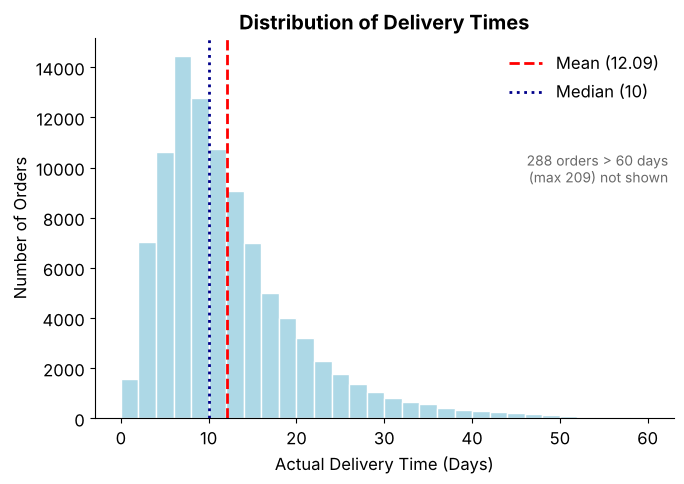

In [9]:
x = delivered['delivery_days']
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(x[x <= 60], bins=range(0, 62, 2), color=LIGHT_BLUE, edgecolor='white')
ax.axvline(x.mean(), color='red', ls='--', lw=2, label=f'Mean ({x.mean():.2f})')
ax.axvline(x.median(), color='darkblue', ls=':', lw=2, label=f'Median ({x.median():.0f})')
ax.set(title='Distribution of Delivery Times', xlabel='Actual Delivery Time (Days)', ylabel='Number of Orders')
ax.text(0.99, 0.62, f'{(x > 60).sum():,} orders > 60 days\n(max {x.max():.0f}) not shown',
        transform=ax.transAxes, ha='right', fontsize=10, color='dimgray')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / 'fig1_delivery_times.png', dpi=150); plt.show()

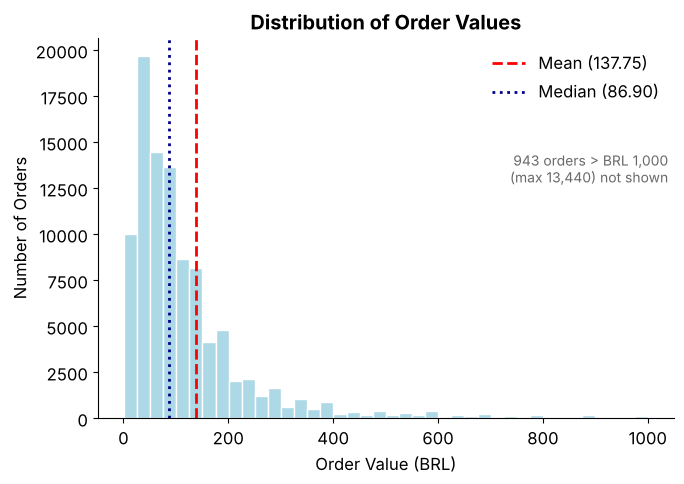

In [10]:
v = order_value['order_value']
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(v[v <= 1000], bins=40, color=LIGHT_BLUE, edgecolor='white')
ax.axvline(v.mean(), color='red', ls='--', lw=2, label=f'Mean ({v.mean():.2f})')
ax.axvline(v.median(), color='darkblue', ls=':', lw=2, label=f'Median ({v.median():.2f})')
ax.set(title='Distribution of Order Values', xlabel='Order Value (BRL)', ylabel='Number of Orders')
ax.text(0.99, 0.62, f'{(v > 1000).sum():,} orders > BRL 1,000\n(max {v.max():,.0f}) not shown',
        transform=ax.transAxes, ha='right', fontsize=10, color='dimgray')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / 'fig2_order_values.png', dpi=150); plt.show()

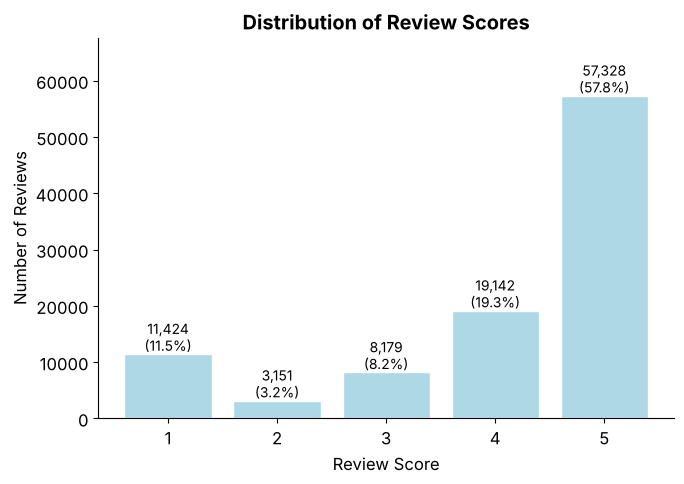

In [11]:
counts = reviews['review_score'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(counts.index, counts.values, color=LIGHT_BLUE, edgecolor='white')
for s, n in counts.items():
    ax.text(s, n + 600, f'{n:,}\n({n / counts.sum():.1%})', ha='center', fontsize=10)
ax.set(title='Distribution of Review Scores', xlabel='Review Score', ylabel='Number of Reviews', ylim=(0, counts.max() * 1.18))
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig3_review_scores.png', dpi=150); plt.show()

Median delivery time: on time 9 days, late 29 days


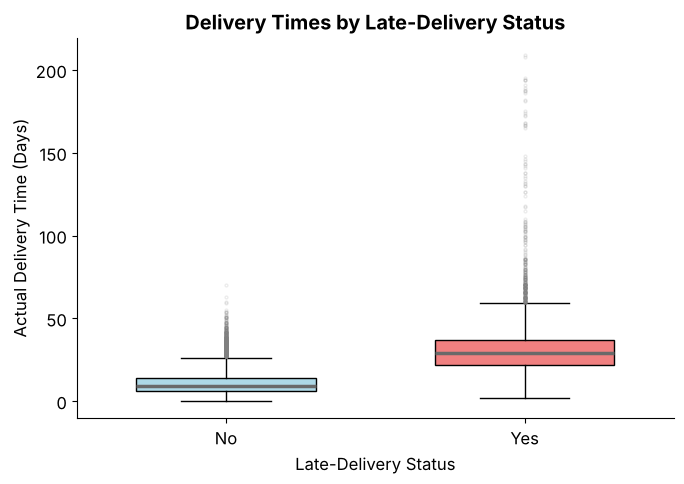

In [12]:
on_time, late = delivered.loc[~delivered['late_delivery'], 'delivery_days'], delivered.loc[delivered['late_delivery'], 'delivery_days']
print(f'Median delivery time: on time {on_time.median():.0f} days, late {late.median():.0f} days')
fig, ax = plt.subplots(figsize=(7, 5))
bp = ax.boxplot([on_time, late], tick_labels=['No', 'Yes'], patch_artist=True, widths=0.6,
                flierprops=dict(marker='o', markersize=2, alpha=0.15, markeredgecolor='gray'),
                medianprops=dict(color='dimgray', lw=2.5))
for box, color in zip(bp['boxes'], [LIGHT_BLUE, LIGHT_RED]): box.set_facecolor(color)
ax.set(title='Delivery Times by Late-Delivery Status', xlabel='Late-Delivery Status', ylabel='Actual Delivery Time (Days)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig4_delivery_by_late_status.png', dpi=150); plt.show()

Pearson r = -0.33 (p < 0.001)


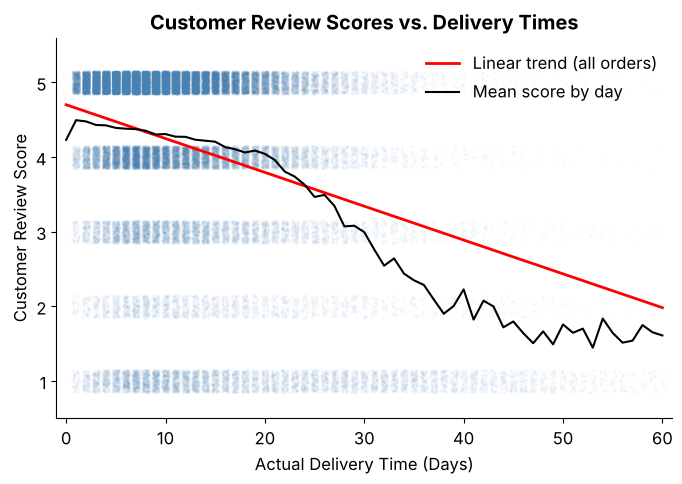

,orders,mean_score,share_1_star
delivery_band,,,
≤10,52082,4.38,0.06
11–20,31885,4.19,0.08
21–30,8360,3.58,0.19
>30,4032,2.18,0.57


In [13]:
dr = delivered.merge(reviews, on='order_id')
r, p = stats.pearsonr(dr['delivery_days'], dr['review_score'])
print(f'Pearson r = {r:.2f} (p < 0.001)')

rng = np.random.default_rng(1)
s = dr[dr['delivery_days'] <= 60]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(s['delivery_days'] + rng.uniform(-.35, .35, len(s)), s['review_score'] + rng.uniform(-.15, .15, len(s)),
           s=4, alpha=0.03, color='steelblue', linewidths=0)
slope, intercept = np.polyfit(dr['delivery_days'], dr['review_score'], 1)
ax.plot([0, 60], [intercept, intercept + slope * 60], color='red', lw=2, label='Linear trend (all orders)')
daily = dr.groupby('delivery_days')['review_score'].mean().loc[:60]
ax.plot(daily.index, daily.values, color='black', lw=1.5, label='Mean score by day')
ax.set(title='Customer Review Scores vs. Delivery Times', xlabel='Actual Delivery Time (Days)',
       ylabel='Customer Review Score', xlim=(-1, 61), ylim=(0.5, 5.6))
ax.legend(frameon=False, loc='upper right'); fig.tight_layout(); fig.savefig(FIG_DIR / 'fig5_review_vs_delivery.png', dpi=150); plt.show()

dr['delivery_band'] = pd.cut(dr['delivery_days'], [-1, 10, 20, 30, 1000], labels=['≤10', '11–20', '21–30', '>30'])
dr.groupby('delivery_band', observed=True)['review_score'].agg(
    orders='size', mean_score='mean', share_1_star=lambda s: (s == 1).mean())

Longer deliveries are associated with lower ratings (r = −0.33). The drop is steepest after about 20 days. Orders delivered within 10 days average 4.38 and 5.8% get 1 star. Orders taking more than 30 days average 2.18, and 56.8% get 1 star. This is an observational association, not proof of causation.

## 9. Satisfaction: on-time vs late

In [14]:
by_status = orders.merge(reviews, on='order_id').groupby('late_delivery')['review_score'].agg(['mean', 'size'])
print('All orders (undelivered counted as not late):'); print(by_status)
print('\nDelivered orders only:'); print(dr.groupby('late_delivery')['review_score'].agg(['mean', 'size']))

All orders (undelivered counted as not late):
               mean   size
late_delivery             
False          4.21  91523
True           2.57   7701

Delivered orders only:
               mean   size
late_delivery             
False          4.29  88658
True           2.57   7701


On-time customers rate 4.21 (4.29 when undelivered orders are excluded). That is above the 4.20 target. Late customers rate 2.57.

## 10. Confidence intervals vs targets

In [15]:
def t_ci(x):
    x = x.dropna()
    return stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))

rows = []
lo, hi = t_ci(delivered['delivery_days'])
rows.append(['Mean delivery time (days)', delivered['delivery_days'].mean(), lo, hi, 't-interval', '≤ 13', 'Target met' if hi < 13 else 'Not met'])
lo, hi = t_ci(reviews['review_score'])
rows.append(['Mean review score', reviews['review_score'].mean(), lo, hi, 't-interval', '≥ 4.20', 'Target met' if lo >= 4.2 else 'Not met'])
lo, hi = proportion_confint(late_n, len(orders), alpha=0.05, method='wilson')
rows.append(['Late-delivery rate (%)', late_n / len(orders) * 100, lo * 100, hi * 100, 'Wilson', '≤ 10%', 'Target met' if hi < .10 else 'Not met'])
pd.DataFrame(rows, columns=['Metric', 'Estimate', 'Lower 95%', 'Upper 95%', 'Method', 'Target', 'Conclusion'])

,Metric,Estimate,Lower 95%,Upper 95%,Method,Target,Conclusion
0,Mean delivery time (days),12.09,12.03,12.15,t-interval,≤ 13,Target met
1,Mean review score,4.09,4.08,4.09,t-interval,≥ 4.20,Not met
2,Late-delivery rate (%),7.87,7.71,8.04,Wilson,≤ 10%,Target met


In [16]:
# Sensitivity check: delivered orders only
lo, hi = proportion_confint(late_n, len(delivered), method='wilson')
print(f'Late rate, delivered only: {late_n/len(delivered):.2%} (95% CI {lo:.2%} – {hi:.2%})')
lo, hi = t_ci(dr['review_score'])
print(f'Review score, delivered only: {dr.review_score.mean():.2f} (95% CI {lo:.2f} – {hi:.2f})')

Late rate, delivered only: 8.11% (95% CI 7.94% – 8.29%)
Review score, delivered only: 4.16 (95% CI 4.15 – 4.16)


Both sensitivity checks lead to the same conclusions: the late-delivery target is met and the review target is not.

## 11. Conclusions and recommendations
1. **Average delivery time and the late-delivery rate meet their targets.** Both confidence intervals sit entirely on the right side of the target.
2. **Customer satisfaction is below 4.20.** The whole interval is below target.
3. **Lateness is the satisfaction lever.** On-time orders already score above 4.20, while late orders score 2.57. Reducing the 7,827 late orders and the 5,025 orders taking more than 28.5 days is the most direct route to the review target.
4. **Next steps:** look for root causes of the longest deliveries (seller, carrier, region, category). Count an order as late only when it arrives *after* the estimated date, not on it. Track all three metrics monthly with confidence intervals.